# Panorama Stitching — Four Images

##  1 — Import libraries and load four images


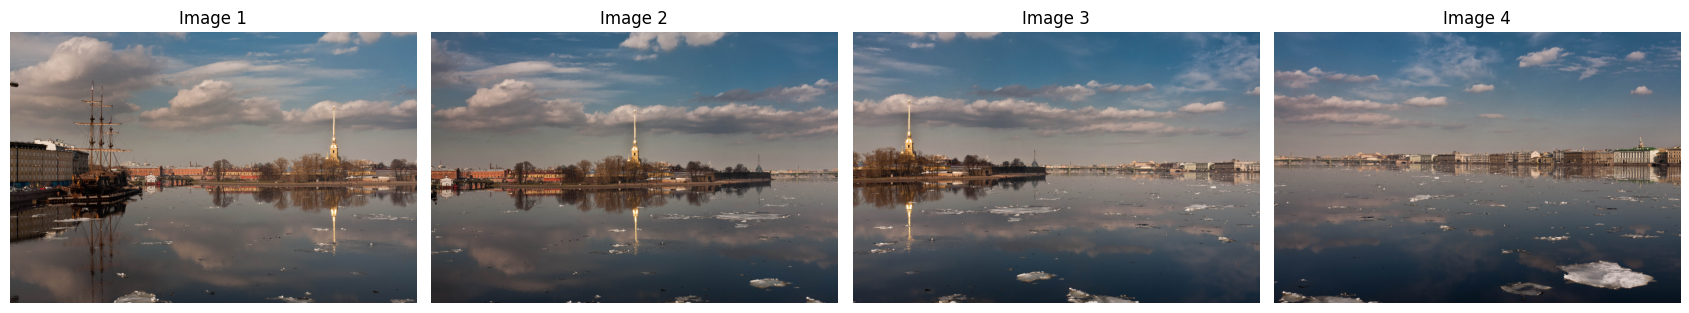

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
np.set_printoptions(precision=3, suppress=True)
base = "https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/stitching/"
folder = Path("opencv_panorama_images")
folder.mkdir(exist_ok=True)
IMAGE_PATHS = [folder / f"boat{i}.jpg" for i in range(1,5)]
for path in IMAGE_PATHS:
    if not path.exists() or path.stat().st_size == 0:
        urlretrieve(base + path.name, path)
def load(path, max_size=900):
    img = cv2.imread(str(path))
    assert img is not None, f"Cannot read {path}"
    scale = min(1, max_size/max(img.shape[:2]))
    return cv2.resize(img, None, fx=scale, fy=scale) if scale < 1 else img
def show(images, titles):
    plt.figure(figsize=(17,5))
    for i, (img, title) in enumerate(zip(images, titles), 1):
        plt.subplot(1, len(images), i)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(title); plt.axis("off")
    plt.tight_layout()
    plt.show()
images = [load(p) for p in IMAGE_PATHS]
show(images, [f"Image {i+1}" for i in range(len(images))])

## 2 — Harris Corner Detection


Harris corners per image: [600, 386, 424, 513]


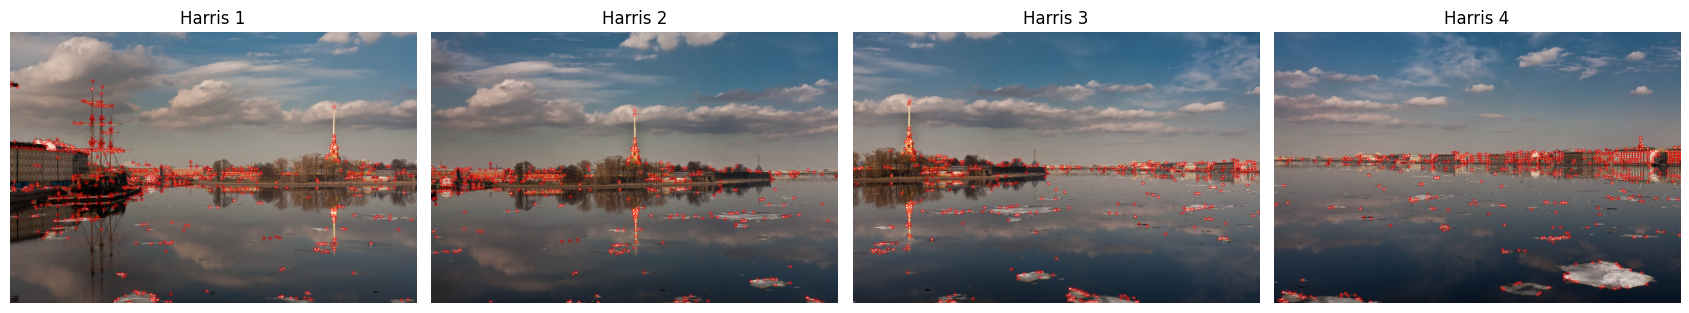

In [ ]:
def harris_corners(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    corners = cv2.goodFeaturesToTrack(gray, maxCorners=1800,
        qualityLevel=0.01, minDistance=5,
        useHarrisDetector=True, k=0.04)
    if corners is None:
        return []
    return [cv2.KeyPoint(float(x), float(y), 16) for x, y in corners.reshape(-1, 2)]
harris_points = [harris_corners(im) for im in images]
print('Harris corners per image:', [len(k) for k in harris_points])
show([cv2.drawKeypoints(im, kp, None, (0, 0, 255)) for im, kp in zip(images, harris_points)],
     [f'Harris {i+1}' for i in range(4)])

## 3 — SIFT descriptors at Harris corners


In [ ]:
sift = cv2.SIFT_create()
features = []
for i, (im, corners) in enumerate(zip(images, harris_points)):
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.compute(gray, corners)
    if descriptors is None or len(descriptors) < 2:
        raise ValueError(f'Image {i+1} has too few descriptors; choose textured images')
    features.append((keypoints, descriptors))
    print(f'Image {i+1}: {len(keypoints)} keypoints, descriptors {descriptors.shape}')

Image 1: 600 keypoints, descriptors (600, 128)
Image 2: 386 keypoints, descriptors (386, 128)
Image 3: 424 keypoints, descriptors (424, 128)
Image 4: 513 keypoints, descriptors (513, 128)


## 4 — Feature Matching + Lowe’s Ratio Test

Pair 1-2: 165 Lowe-filtered matches


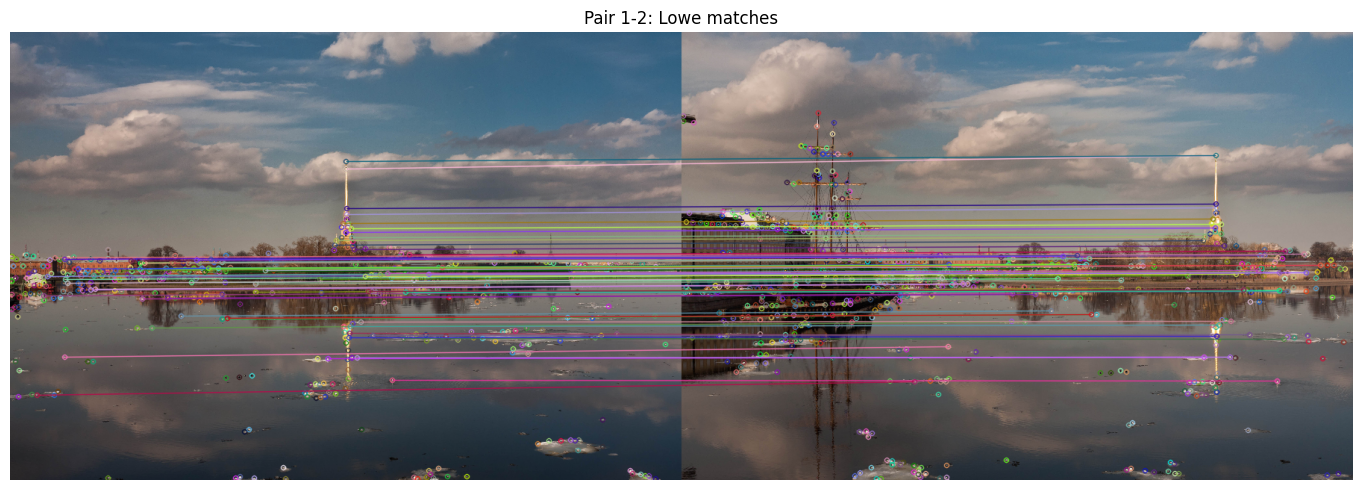

Pair 2-3: 163 Lowe-filtered matches


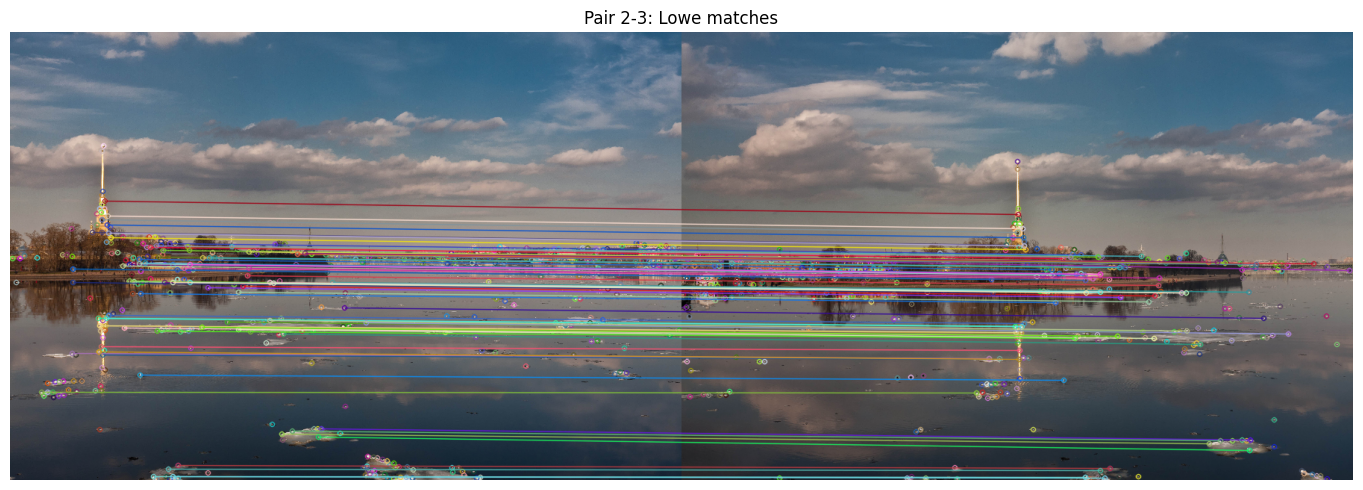

Pair 3-4: 86 Lowe-filtered matches


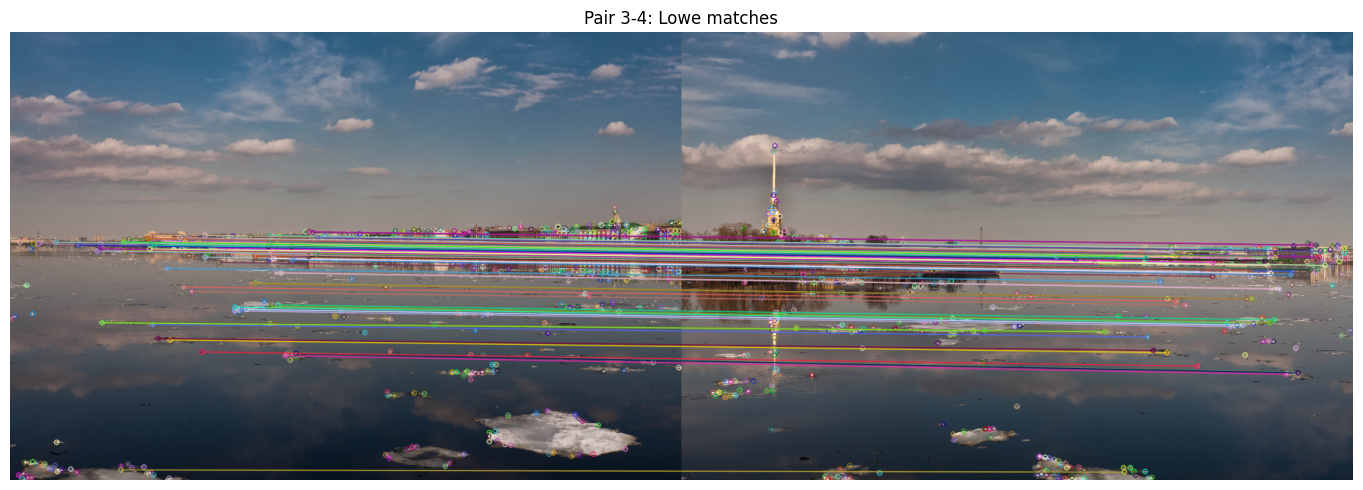

In [ ]:
RATIO = 0.75
matcher = cv2.BFMatcher(cv2.NORM_L2)
pair_matches = []
for i in range(len(images) - 1):
    left_kp, left_des = features[i]
    right_kp, right_des = features[i+1]
    neighbors = matcher.knnMatch(right_des, left_des, k=2)
    good = [p[0] for p in neighbors if len(p) == 2 and p[0].distance < RATIO * p[1].distance]
    if len(good) < 4:
        raise ValueError(f'Pair {i+1}-{i+2}: only {len(good)} good matches; use photos with more overlap')
    pair_matches.append(good)
    print(f'Pair {i+1}-{i+2}: {len(good)} Lowe-filtered matches')
    preview = cv2.drawMatches(images[i+1], right_kp, images[i], left_kp, good[:80], None)
    show([preview], [f'Pair {i+1}-{i+2}: Lowe matches'])

##  5 — Homography + RANSAC

Pair 1-2: 121/165 inliers


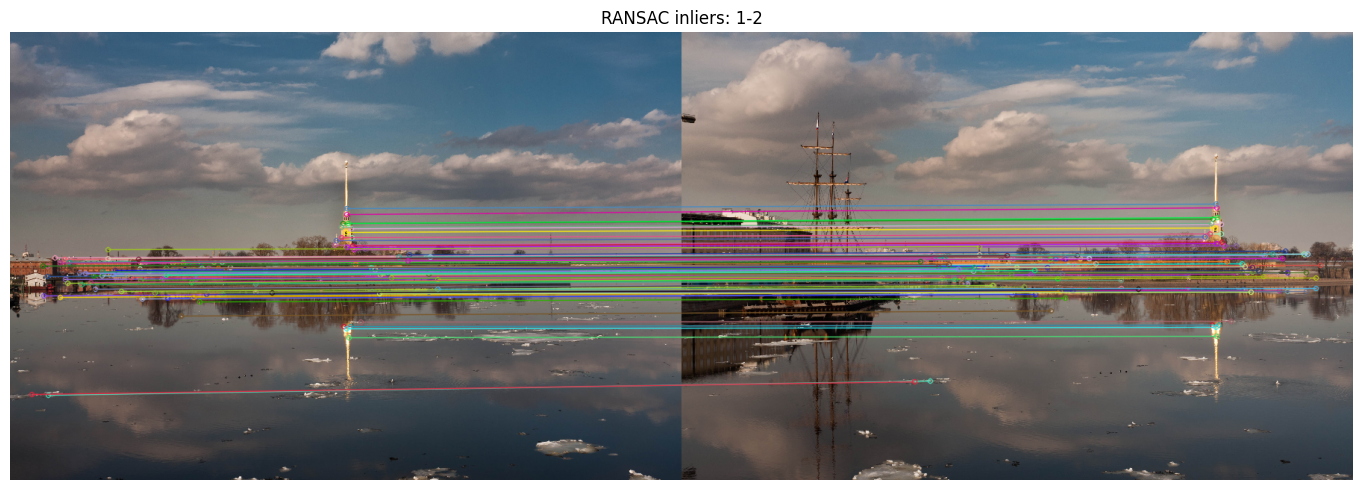

Pair 2-3: 96/163 inliers


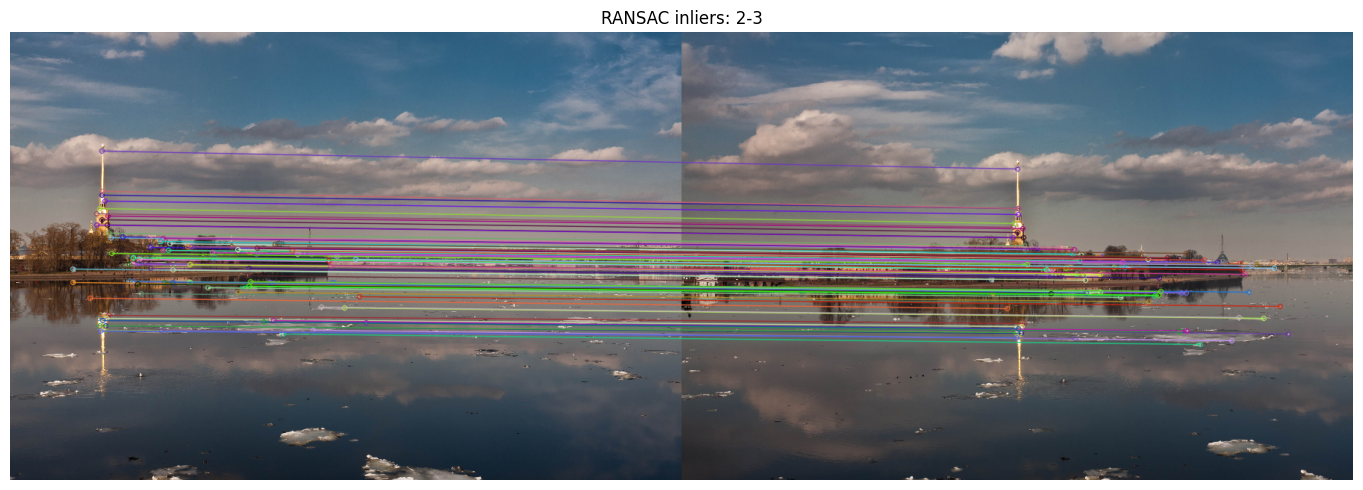

Pair 3-4: 73/86 inliers


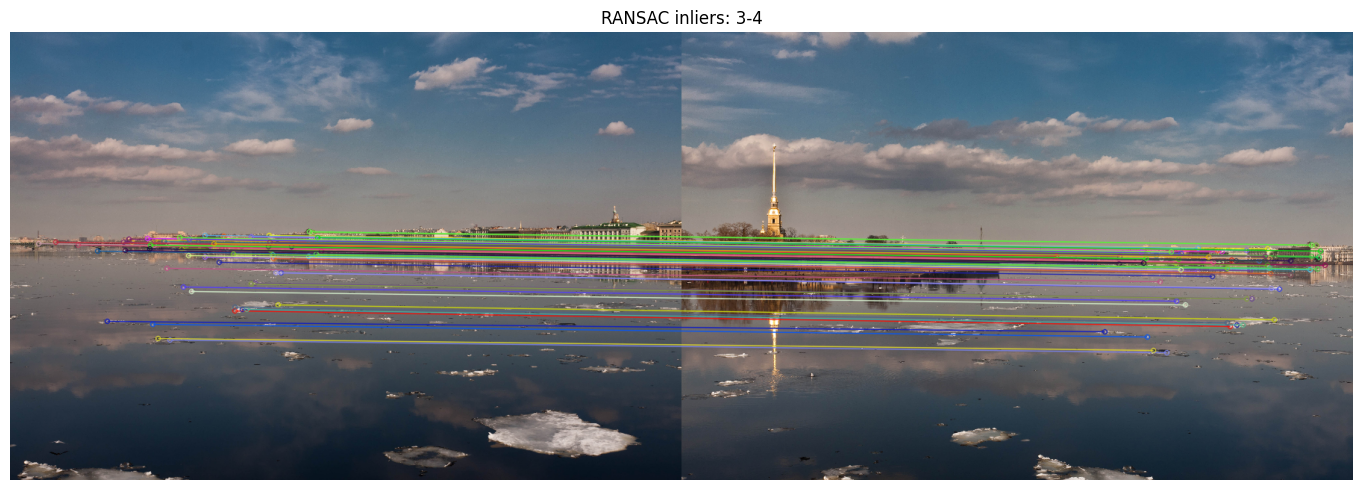

Reference image: 2


In [ ]:
pair_H = []
for i, good in enumerate(pair_matches):
    kp1, _ = features[i]
    kp2, _ = features[i+1]
    src = np.float32([kp2[m.queryIdx].pt for m in good])
    dst = np.float32([kp1[m.trainIdx].pt for m in good])
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
    if H is None or mask.sum() < 10:
        raise ValueError("Not enough inliers")
    pair_H.append(H)
    print(f"Pair {i+1}-{i+2}: {mask.sum()}/{len(good)} inliers")
    preview = cv2.drawMatches(images[i+1], kp2, images[i], kp1, good, None, matchesMask=mask.ravel().tolist(), flags=2)
    show([preview], [f"RANSAC inliers: {i+1}-{i+2}"])
reference_idx = (len(images)-1)//2
transforms = [np.eye(3) for img in images]
for i in range(reference_idx-1, -1, -1):
    transforms[i] = transforms[i+1] @ np.linalg.inv(pair_H[i])
for i in range(reference_idx+1, len(images)):
    transforms[i] = transforms[i-1] @ pair_H[i-1]
print("Reference image:", reference_idx+1)

##  6 — Manual Warping + Feather Blending


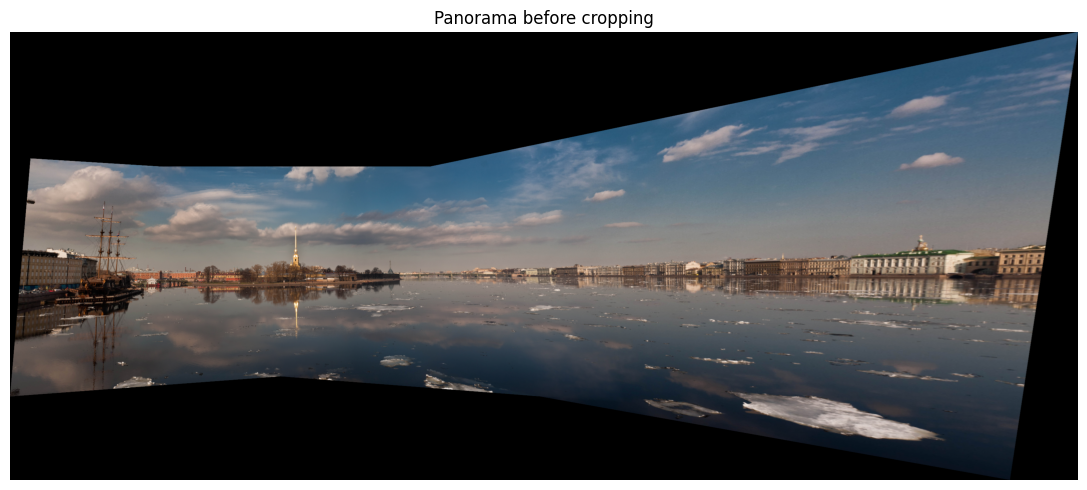

In [ ]:
corners_all = []
for img, H in zip(images, transforms):
    h, w = img.shape[:2]
    corners = np.float32([[0,0], [w-1,0], [w-1,h-1], [0,h-1]]).reshape(-1,1,2)
    corners_all.append(cv2.perspectiveTransform(corners, H))
points = np.vstack(corners_all).reshape(-1,2)
xmin, ymin = np.floor(points.min(axis=0)).astype(int)
xmax, ymax = np.ceil(points.max(axis=0)).astype(int)
width, height = xmax-xmin+1, ymax-ymin+1
shift = np.float64([[1,0,-xmin], [0,1,-ymin], [0,0,1]])
canvas = np.zeros((height,width,3), np.float32)
weights = np.zeros((height,width), np.float32)
for img, H in zip(images, transforms):
    H = shift @ H
    warped = cv2.warpPerspective(img, H, (width,height))
    mask = cv2.warpPerspective(np.ones(img.shape[:2], np.uint8), H, (width,height), flags=cv2.INTER_NEAREST)
    weight = cv2.distanceTransform(mask, cv2.DIST_L2, 3)
    weight = np.where(mask > 0, np.maximum(weight,1), 0)
    canvas += warped * weight[:,:,None]
    weights += weight
canvas = np.uint8(np.clip(canvas / np.maximum(weights[:,:,None],1e-6), 0,255))
valid_mask = weights > 0
show([canvas], ["Panorama before cropping"])

##  7 — Cropping and save



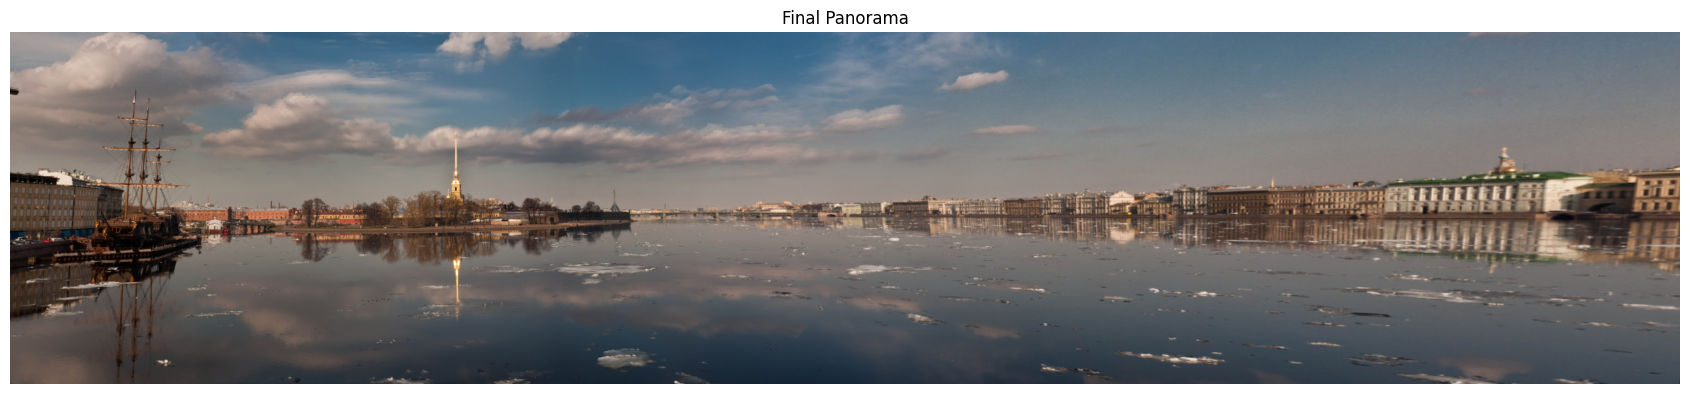

True

In [ ]:
x, y, w, h = cv2.boundingRect(valid_mask.astype(np.uint8))
panorama = canvas[y:y+h, x:x+w]
mask = valid_mask[y:y+h, x:x+w]
while mask.size and not mask.all():
    borders = [mask[0,:].mean(), mask[-1,:].mean(), mask[:,0].mean(), mask[:,-1].mean()]
    side = np.argmin(borders)
    if side == 0:
        panorama, mask = panorama[1:,:], mask[1:,:]
    elif side == 1:
        panorama, mask = panorama[:-1,:], mask[:-1,:]
    elif side == 2:
        panorama, mask = panorama[:,1:], mask[:,1:]
    else:
        panorama, mask = panorama[:,:-1], mask[:,:-1]
if panorama.size == 0:
    raise ValueError("Cropping failed")
show([panorama], ["Final Panorama"])
cv2.imwrite("final_panorama.jpg", panorama)